-------
## Projekt 1 - Wstęp do Uczenia Maszynowego 2026Z

## Kod KM1

-------


**Imię i Nazwisko:** Paweł Buczyński

**Prowadzący:** AK

**Kierunek:** IAD

**Numer albumu:** 338979

------

> Proszę o dostosowanie nazw rozdziałów i podrozdziałów do nazw umieszczonych w raporcie.

### *Import pakietów*

-------

In [234]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import tree
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.metrics import (
    RocCurveDisplay,
    confusion_matrix,
    accuracy_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

In [ ]:
import itertools
from tqdm import tqdm # to see progress on the long tasks

### *1. Eksploracyjna analiza danych*
-------

In [9]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv")
X_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 6400 entries, 0 to 6399
Data columns (total 23 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   LIMIT_BAL  6400 non-null   float64
 1   SEX        6400 non-null   int64  
 2   EDUCATION  6400 non-null   int64  
 3   MARRIAGE   6400 non-null   int64  
 4   AGE        6400 non-null   int64  
 5   PAY_0      6400 non-null   int64  
 6   PAY_2      6400 non-null   int64  
 7   PAY_3      6400 non-null   int64  
 8   PAY_4      6400 non-null   int64  
 9   PAY_5      5764 non-null   float64
 10  PAY_6      6400 non-null   int64  
 11  BILL_AMT1  6400 non-null   float64
 12  BILL_AMT2  6400 non-null   float64
 13  BILL_AMT3  6400 non-null   float64
 14  BILL_AMT4  6400 non-null   float64
 15  BILL_AMT5  6400 non-null   float64
 16  BILL_AMT6  5747 non-null   float64
 17  PAY_AMT1   6400 non-null   float64
 18  PAY_AMT2   6400 non-null   float64
 19  PAY_AMT3   6400 non-null   float64
 20  PAY_AMT4   5765 non

In [ ]:
X_train.isna().mean()
# ~10% is NA in 3 columns

LIMIT_BAL    0.000000
SEX          0.000000
EDUCATION    0.000000
MARRIAGE     0.000000
AGE          0.000000
PAY_1        0.000000
PAY_2        0.000000
PAY_3        0.000000
PAY_4        0.000000
PAY_5        0.099375
PAY_6        0.000000
BILL_AMT1    0.000000
BILL_AMT2    0.000000
BILL_AMT3    0.000000
BILL_AMT4    0.000000
BILL_AMT5    0.000000
BILL_AMT6    0.102031
PAY_AMT1     0.000000
PAY_AMT2     0.000000
PAY_AMT3     0.000000
PAY_AMT4     0.099219
PAY_AMT5     0.000000
PAY_AMT6     0.000000
dtype: float64

In [11]:
y_train

,default.payment.next.month
0,1
1,0
2,0
3,0
4,0
...,...
6395,1
6396,0
6397,1
6398,0


In [ ]:
# rename column for easier indexing to match other categories
X_train.rename(columns={"PAY_0": "PAY_1"}, inplace=True)

In [ ]:
X_train.describe()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
count,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,6400.000000,5764.000000,...,6400.000000,6400.000000,6400.000000,5747.000000,6400.000000,6400.000000,6400.000000,5765.000000,6400.000000,6400.000000
mean,167058.277002,1.600781,1.837344,1.565313,34.828437,-0.016875,-0.147813,-0.165469,-0.229687,-0.277412,...,46668.658987,42570.465505,39376.521125,38299.316665,5915.514595,5880.763194,5467.802412,4885.008345,5095.018971,5683.631062
std,130788.623708,0.489776,0.796703,0.518858,9.090674,1.132852,1.179351,1.189615,1.158643,1.122036,...,69070.541625,63682.290146,59482.257375,59008.762193,16238.050622,18325.748442,16933.338728,16338.827889,16667.879638,20156.367699
min,-157.510827,1.000000,0.000000,0.000000,19.000000,-2.000000,-2.000000,-3.000000,-2.000000,-2.000000,...,-31630.644835,-55474.962574,-35278.286793,-233709.690512,-6738.564949,-10167.637159,-7045.833855,-7348.718103,-5067.446251,-6447.078871
25%,54027.835110,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,4985.879564,4228.746666,3888.382113,3240.553965,831.049893,590.110451,471.693831,316.222230,363.164390,315.556262
50%,138508.702518,2.000000,2.000000,2.000000,33.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,21111.898181,19429.490212,17977.085430,17057.197383,2488.564978,2435.121810,1963.011326,1690.255004,1768.453638,1765.101581
75%,236847.697924,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,59476.042972,53533.843872,49679.867123,48644.156400,5589.821721,5579.007592,4841.167174,4331.011086,4436.389159,4500.501201
max,783258.369189,2.000000,6.000000,3.000000,73.000000,8.000000,7.000000,7.000000,7.000000,7.000000,...,548472.305856,536004.787076,502351.970698,496311.167092,306664.791220,579958.411614,402667.936174,432461.892791,328741.932673,527618.450542


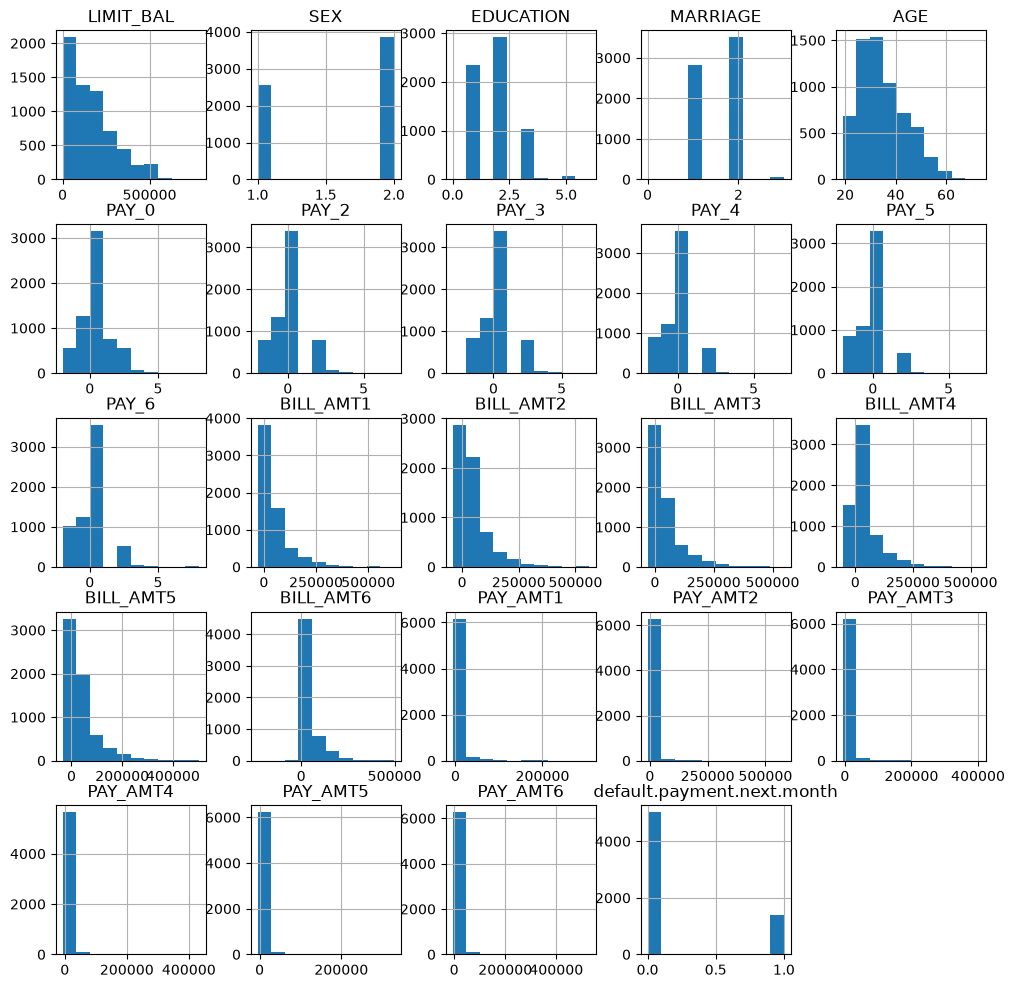

In [179]:
pd.concat([X_train, y_train], axis="columns").hist(figsize=(12, 12));

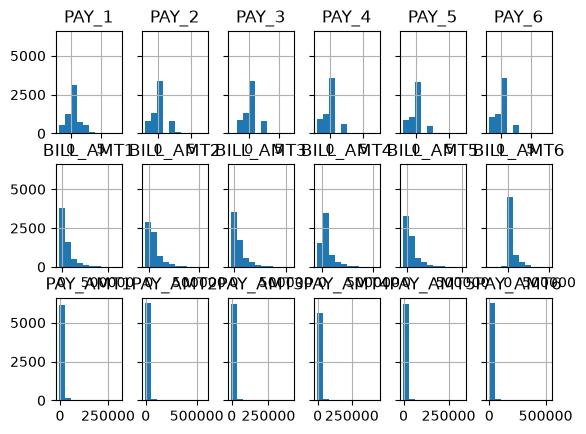

In [226]:
pay_cols = [f"PAY_{i}" for i in range(1, 7)]
bill_amt_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

X_train[pay_cols + bill_amt_cols + pay_amt_cols].hist(layout=(3, 6), sharey=True);

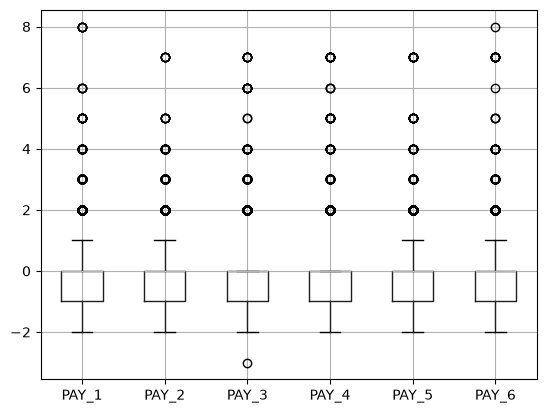

In [ ]:
X_train[pay_cols].boxplot();

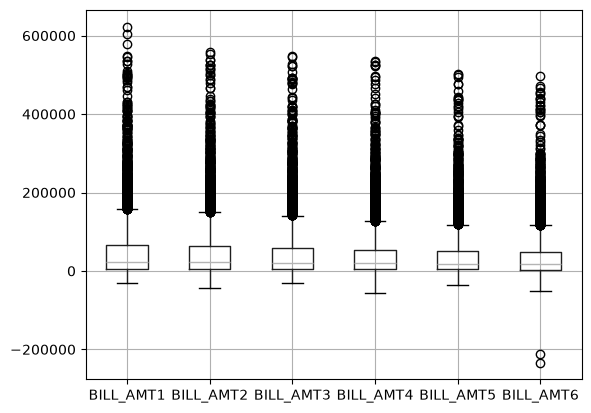

In [232]:
X_train[bill_amt_cols].boxplot();

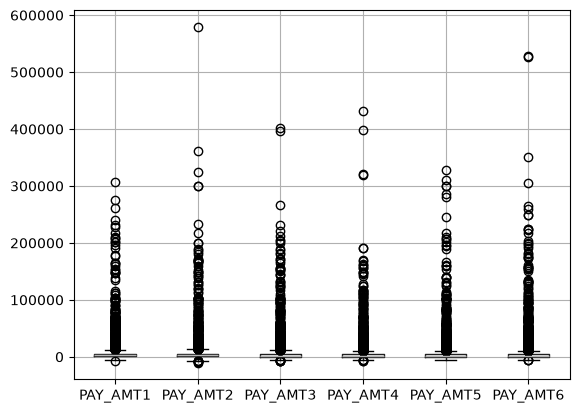

In [233]:
X_train[pay_amt_cols].boxplot();

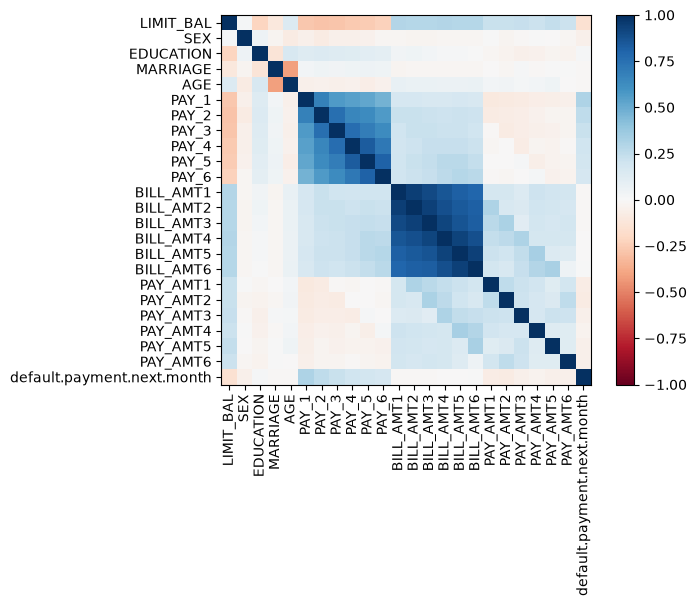

In [242]:
df_train = pd.concat([X_train, y_train], axis="columns")
plt.imshow(df_train.corr(), cmap="RdBu", vmin=-1., vmax=1.)
plt.colorbar()
plt.xticks(np.arange(len(df_train.columns)), df_train.columns, rotation=90)
plt.yticks(np.arange(len(df_train.columns)), df_train.columns);

### *2. Metryka ewaluacji i podział danych*
-------

In [235]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.20, random_state=123
)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=123)

In [236]:
params = {
    "criterion": ["gini", "entropy"],
    "max_depth": np.arange(2, 20, 1),
    "max_leaf_nodes": np.arange(10, 30, 1),
}

total = np.prod(list(map(len, params.values())))
print(total, list(map(len, params.values())))

720 [2, 18, 20]


In [ ]:
# very advanced iterator tricks
product = (dict(zip(params, mp)) for mp in itertools.product(*params.values()))

def iteration(params):
    model = tree.DecisionTreeClassifier(**params, random_state=123)
    scores = cross_val_score(model, X_fit, y_fit, cv=cv, n_jobs=24, scoring="roc_auc")
    return {**params, "score": np.mean(scores)}

results = list(tqdm(map(iteration, product), total=total))

100%|██████████| 720/720 [01:16<00:00,  9.39it/s]


In [208]:
df = pd.DataFrame(results)

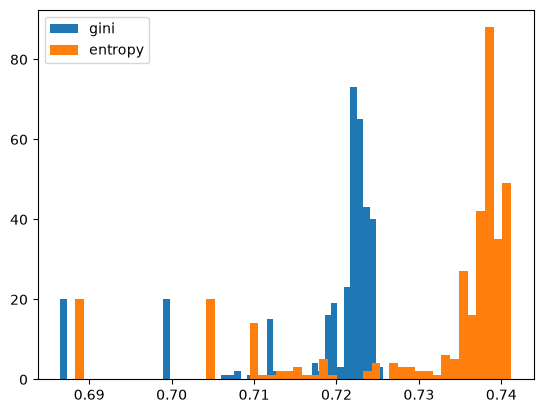

In [209]:
for c in params["criterion"]:
    plt.hist(df.loc[df["criterion"] == c, "score"], label=c, bins=50)
plt.legend()

np.float64(0.7411941908743022)

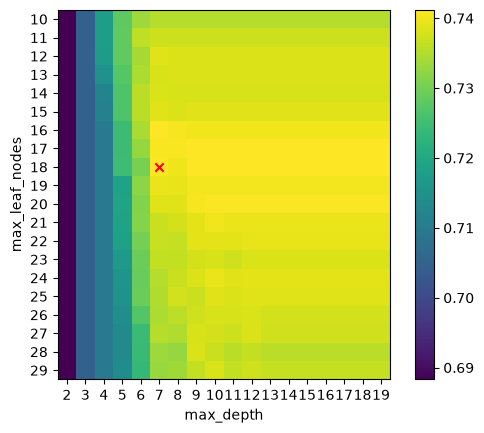

In [212]:
data = df[df["criterion"] == "entropy"].pivot(index="max_leaf_nodes", columns="max_depth", values="score").to_numpy()
maximum = np.unravel_index(np.argmax(data), shape=data.shape)
plt.imshow(data)
plt.scatter(*maximum[::-1], marker="x", color="red")
plt.xlabel("max_depth")
plt.ylabel("max_leaf_nodes")
plt.xticks(np.arange(len(params["max_depth"])), params["max_depth"])
plt.yticks(np.arange(len(params["max_leaf_nodes"])), params["max_leaf_nodes"])
plt.colorbar()
plt.clim(np.min(data), np.max(data))
data[maximum]

In [213]:
best = df.iloc[df["score"].idxmax()]
best

criterion          entropy
max_depth                7
max_leaf_nodes          18
score             0.741194
Name: 468, dtype: object

In [221]:
model = tree.DecisionTreeClassifier(**best[["criterion", "max_depth", "max_leaf_nodes"]])
model.fit(X_fit, y_fit)
model

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",np.int64(7)
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",np.int64(18)
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is t

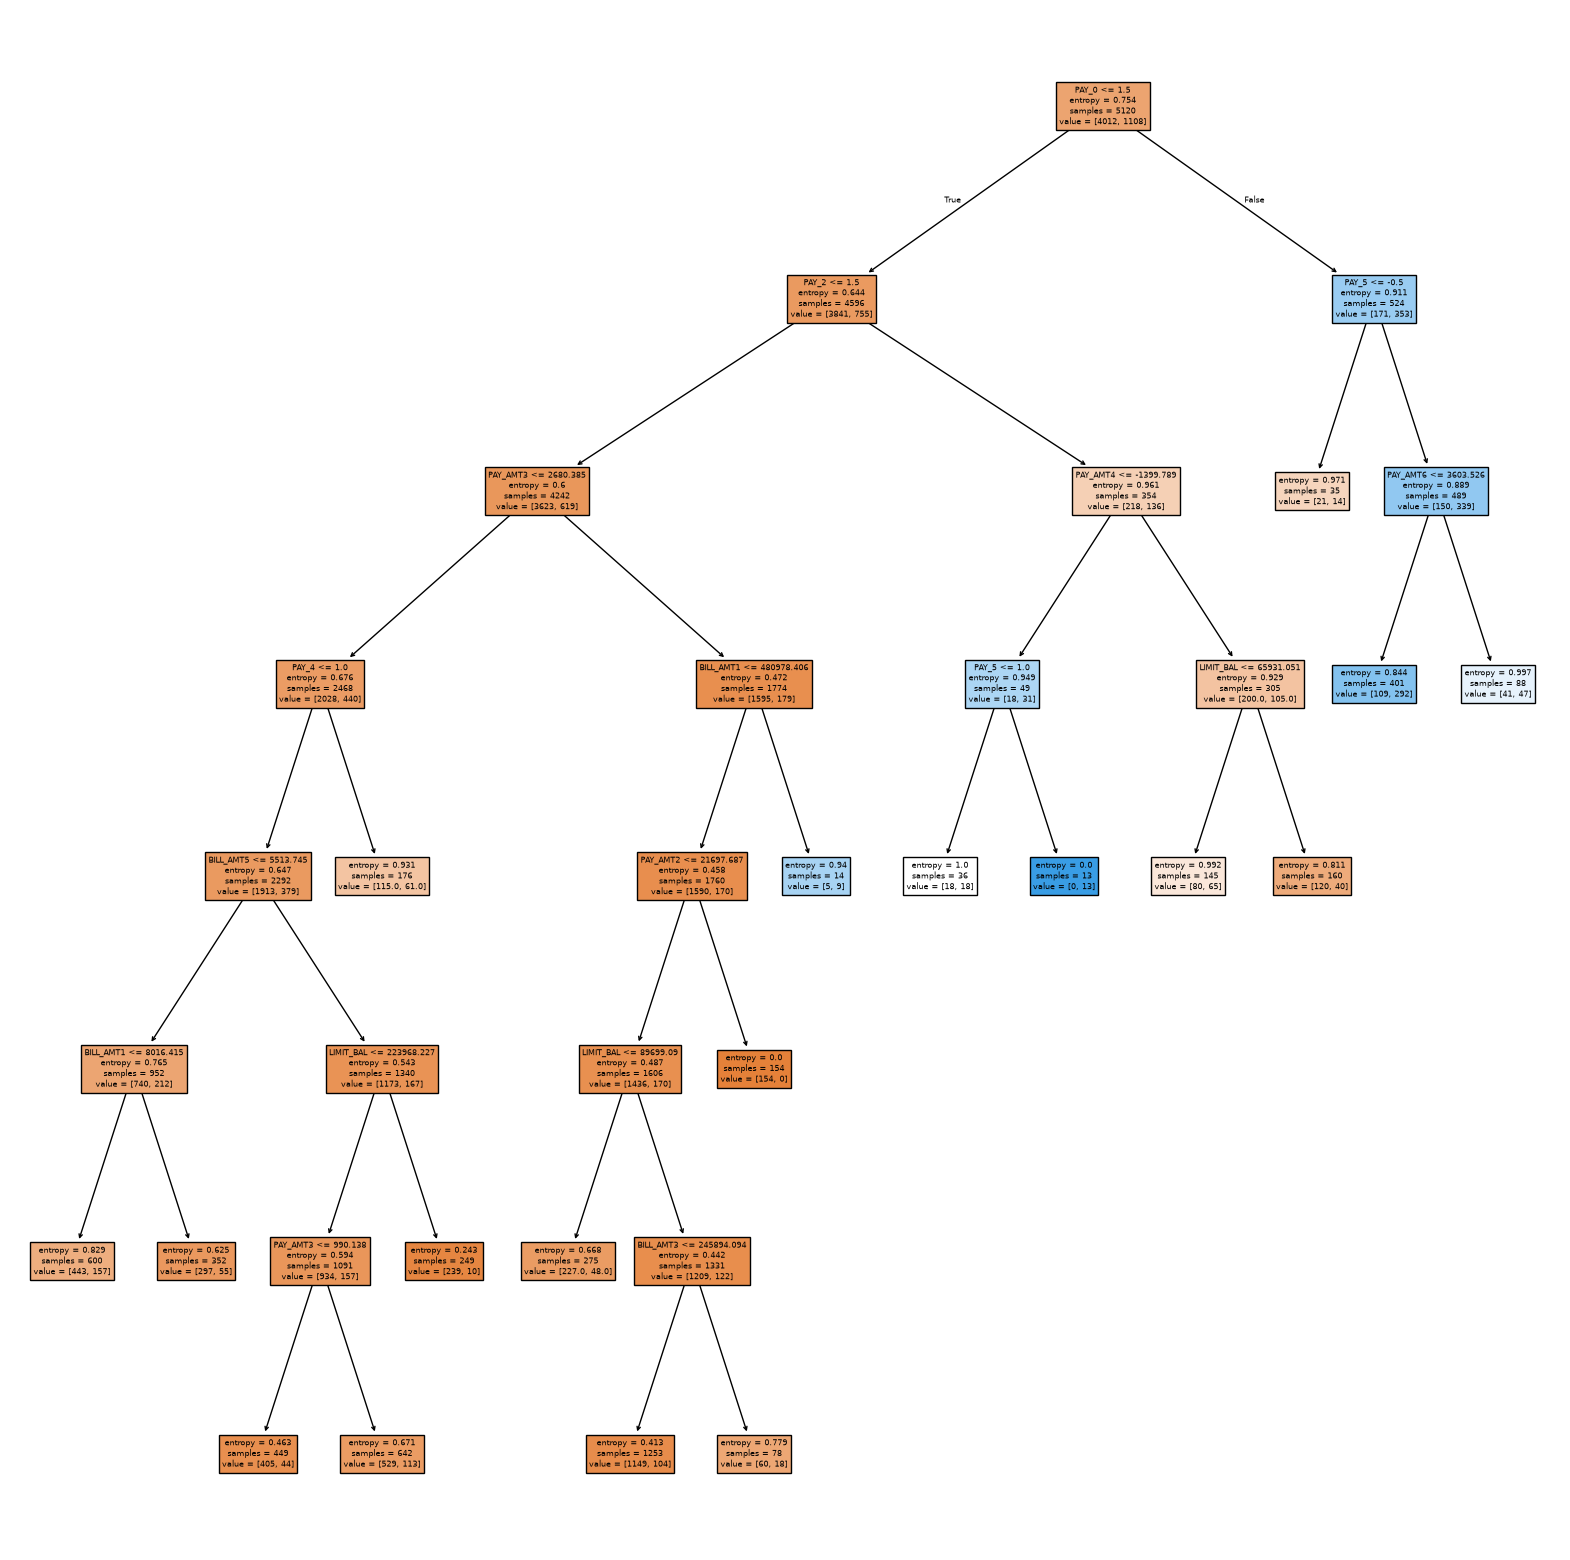

In [215]:
tree.plot_tree(model, filled=True, feature_names=model.feature_names_in_, ax=plt.subplots(figsize=(20, 20))[1]);

In [222]:
print(f"AUC (fit): {roc_auc_score(y_fit, model.predict_proba(X_fit)[:, 1])}")
print(f"AUC (val): {roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])}")
print(f"AUC (train=fit+val): {roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])}")

AUC (fit): 0.775942479420943
AUC (val): 0.7537966832902283
AUC (train=fit+val): 0.7716125500794301


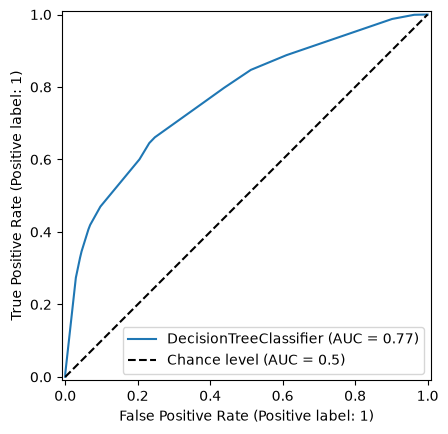

In [220]:
RocCurveDisplay.from_estimator(model, X_train, y_train, plot_chance_level=True)

### *2.1 Podrozdział 2 (edit)*
-------

### *3. Podsumowanie i wnioski*
-------